In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "custseg").exists():   # project root = folder that holds the package
    if ROOT == ROOT.parent:
        raise RuntimeError("run the notebook from inside the project folder")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
from custseg import config, db
img = lambda p, w=900: display(Image(filename=str(ROOT / p), width=w))

# 05 · Multivariate Analysis

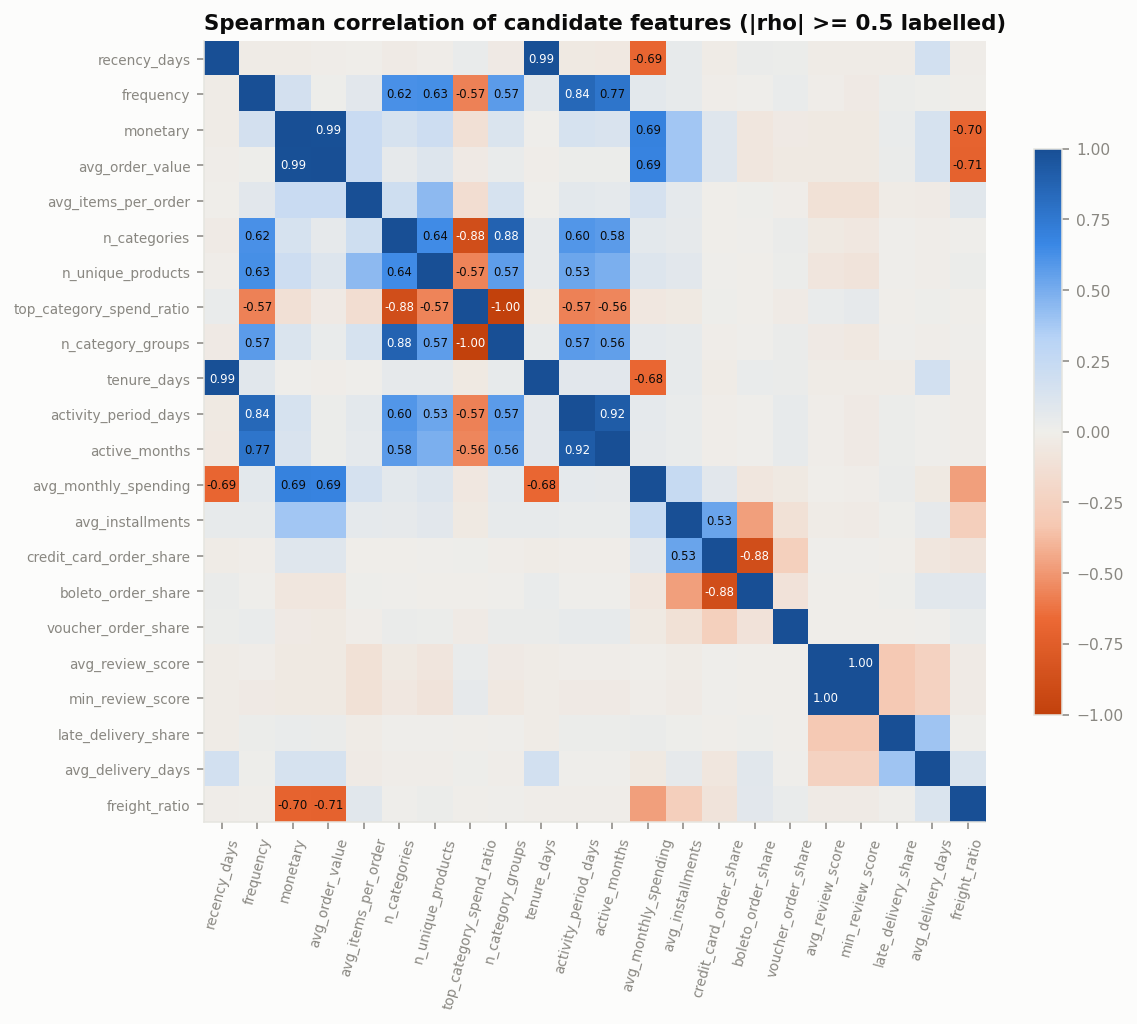

In [2]:
img('04_data_profiling_eda/reports/figures/multivariate_correlation.png', 760)

In [3]:
pd.read_csv(ROOT / '04_data_profiling_eda/reports/pca_loadings.csv', index_col=0).round(3)

,PC1,PC2,PC3
recency_days,0.011,0.040,-0.120
frequency,0.138,0.023,0.484
monetary,0.653,0.029,0.060
avg_items_per_order,0.165,-0.210,0.745
avg_installments,0.459,0.021,-0.056
avg_review_score,-0.077,0.701,0.029
late_delivery_share,0.049,-0.660,-0.278
freight_ratio,-0.555,-0.160,0.335


In [4]:
pd.DataFrame(json.loads((ROOT / '04_data_profiling_eda/reports/eda_summary.json').read_text())['high_corr_pairs'], columns=['a','b','rho'])

,a,b,rho
0,recency_days,tenure_days,0.986858
1,frequency,activity_period_days,0.844685
2,monetary,avg_order_value,0.986894
3,n_categories,top_category_spend_ratio,-0.881512
4,n_categories,n_category_groups,0.881573
5,top_category_spend_ratio,n_category_groups,-0.999938
6,activity_period_days,active_months,0.917835
7,credit_card_order_share,boleto_order_share,-0.875329
8,avg_review_score,min_review_score,0.999121
